Literature fit: uptake ∝ (cross-linker)^-0.66
  50 µL = 0.55 wt% of acrylic acid -> literature trend predicts ≈ 6,120%
  100 µL = 1.09 wt% of acrylic acid -> literature trend predicts ≈ 3,864%
  200 µL = 2.18 wt% of acrylic acid -> literature trend predicts ≈ 2,439%


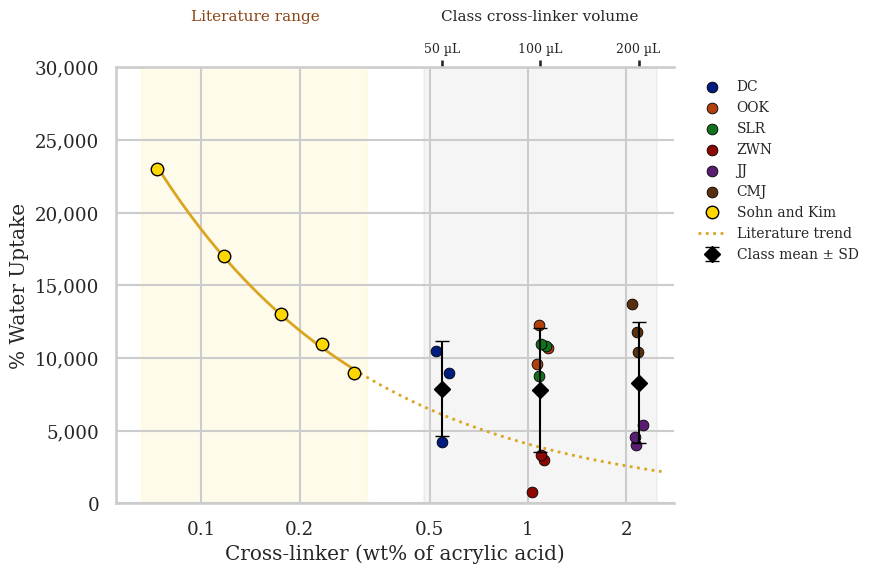

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.transforms as mtrans
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk", font_scale=0.8)
plt.rcParams["font.family"] = "serif"


data = {
    ("DC", 50):   [4200, 9000, 10500],
    ("OOK", 100): [10700, 9600, 12300],
    ("SLR", 100): [10800, 8800, 11000],
    ("ZWN", 100): [800, 3000, 3300],
    ("JJ", 200):  [4000, 5400, 4600],
    ("CMJ", 200): [10400, 13700, 11800],
}
df = pd.DataFrame([{"Group": g, "Cross-linker (µL)": c, "% Water Uptake": v}
                   for (g, c), vals in data.items() for v in vals])


RHO_EDA, AA_MASS = 1.09, 10.0
vol_to_wt = {v: v / 1000 * RHO_EDA / AA_MASS * 100 for v in (50, 100, 200)}
df["XL (wt%)"] = df["Cross-linker (µL)"].map(vol_to_wt)


lit_soln_wt = np.array([0.025, 0.04, 0.06, 0.08, 0.10])
lit_x = lit_soln_wt * 61.0 / 20.8
lit_y = np.array([23000, 17000, 13000, 11000, 9000])

b, ln_a = np.polyfit(np.log(lit_x), np.log(lit_y), 1)
fit = lambda x: np.exp(ln_a) * x ** b
x_fit = np.geomspace(lit_x.min(), lit_x.max(), 50)
x_ext = np.geomspace(lit_x.max(), 2.6, 50)
print(f"Literature fit: uptake ∝ (cross-linker)^{b:.2f}")
for v, x in vol_to_wt.items():
    print(f"  {v} µL = {x:.2f} wt% of acrylic acid -> literature trend predicts ≈ {fit(x):,.0f}%")


fig, ax = plt.subplots(figsize=(9, 6))
groups = [g for g, _ in data]
colors = dict(zip(groups, sns.color_palette("dark", len(groups))))
rng = np.random.default_rng(1)
for g in groups:
    sub = df[df["Group"] == g]
    jitter = np.exp(rng.uniform(-0.06, 0.06, len(sub)))
    ax.scatter(sub["XL (wt%)"] * jitter, sub["% Water Uptake"], s=60, color=colors[g],
               edgecolor="black", linewidth=0.6, label=g, zorder=3)

lvl = df.groupby("XL (wt%)")["% Water Uptake"].agg(["mean", "std"])
ax.errorbar(lvl.index, lvl["mean"], yerr=lvl["std"], fmt="D", color="black",
            ms=8, lw=1.5, capsize=5, label="Class mean ± SD", zorder=4)

ax.plot(lit_x, lit_y, "o", color="gold", mec="black", ms=9, zorder=5, label="Sohn and Kim")
ax.plot(x_fit, fit(x_fit), "-", color="goldenrod", lw=2, zorder=2)
ax.plot(x_ext, fit(x_ext), ":", color="goldenrod", lw=2, zorder=2, label="Literature trend")

ax.axvspan(lit_x.min() * 0.9, lit_x.max() * 1.1, color="gold", alpha=0.08, zorder=0)
ax.axvspan(vol_to_wt[50] * 0.88, vol_to_wt[200] * 1.14, color="gray", alpha=0.08, zorder=0)

ax.set_xscale("log")
ax.set_xticks([0.05, 0.1, 0.2, 0.5, 1, 2])
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, p: f"{x:g}"))
ax.set(xlabel="Cross-linker (wt% of acrylic acid)", ylabel="% Water Uptake",
       ylim=(0, 30000), xlim=(0.055, 2.8))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, p: f"{x:,.0f}"))

top = ax.secondary_xaxis("top")
top.set_xticks(list(vol_to_wt.values()), [f"{v} µL" for v in vol_to_wt])
top.xaxis.set_minor_locator(mtick.NullLocator())
top.tick_params(axis="x", length=5, labelsize=9)
blend = mtrans.blended_transform_factory(ax.transData, ax.transAxes)
ax.text(vol_to_wt[100], 1.10, "Class cross-linker volume", ha="center", va="bottom",
        fontsize=11, transform=blend)
ax.text(np.sqrt(lit_x.min() * lit_x.max()), 1.10, "Literature range", ha="center", va="bottom",
        fontsize=11, color="saddlebrown", transform=blend)

ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=10)
sns.despine()
plt.tight_layout()
plt.savefig("FigureX_crosslinker.png", dpi=300)
plt.show()

ANOVA by group: F(5,12) = 13.40, p = 0.00015, eta² = 84.8%


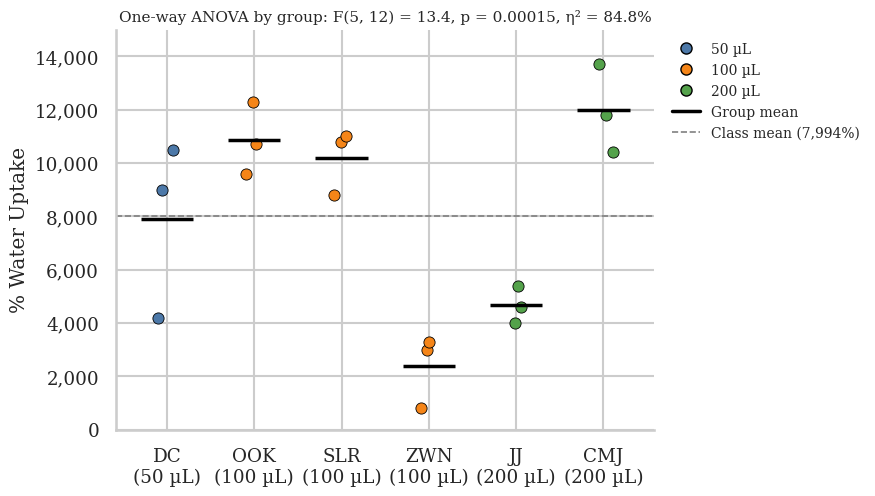

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.lines import Line2D
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="talk", font_scale=0.8)
plt.rcParams["font.family"] = "serif"

data = {
    ("DC", 50):   [4200, 9000, 10500],
    ("OOK", 100): [10700, 9600, 12300],
    ("SLR", 100): [10800, 8800, 11000],
    ("ZWN", 100): [800, 3000, 3300],
    ("JJ", 200):  [4000, 5400, 4600],
    ("CMJ", 200): [10400, 13700, 11800],
}
xl_color = {50: "#4C78A8", 100: "#F58518", 200: "#54A24B"}
groups = list(data.values())
all_vals = np.concatenate(groups)
grand_mean = all_vals.mean()

F, p = stats.f_oneway(*groups)
eta2 = sum(len(g) * (np.mean(g) - grand_mean) ** 2 for g in groups) / ((all_vals - grand_mean) ** 2).sum()
print(f"ANOVA by group: F(5,12) = {F:.2f}, p = {p:.5f}, eta² = {eta2*100:.1f}%")

fig, ax = plt.subplots(figsize=(9, 5.2))
rng = np.random.default_rng(3)
ax.axhline(grand_mean, color="gray", ls="--", lw=1.2, zorder=1)
for i, ((g, c), vals) in enumerate(data.items()):
    vals = np.array(vals)
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(vals)), vals, s=65, color=xl_color[c],
               edgecolor="black", linewidth=0.6, zorder=3)
    ax.hlines(vals.mean(), i - 0.3, i + 0.3, color="black", lw=2.5, zorder=4)

ax.set_xticks(range(len(data)), [f"{g}\n({c} µL)" for g, c in data])
ax.set(ylabel="% Water Uptake", ylim=(0, 15000))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, p: f"{x:,.0f}"))
ax.set_title(f"One-way ANOVA by group: F(5, 12) = {F:.1f}, p = {p:.2g}, η² = {eta2*100:.1f}%", fontsize=11)

handles = [Line2D([], [], marker="o", ls="", color=xl_color[l], mec="black", ms=8, label=f"{l} µL")
           for l in xl_color]
handles += [Line2D([], [], color="black", lw=2.5, label="Group mean"),
            Line2D([], [], color="gray", ls="--", lw=1.2, label=f"Class mean ({grand_mean:,.0f}%)")]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=10)

sns.despine()
plt.tight_layout()
plt.savefig("Figure1_groups_ANOVA.png", dpi=300)
plt.show()

In [9]:
import scipy.stats as stats


pearson_r, pearson_p = stats.pearsonr(df['XL (wt%)'], df['% Water Uptake'])


spearman_r, spearman_p = stats.spearmanr(df['XL (wt%)'], df['% Water Uptake'])

print("Correlation Analysis (Experimental Data):")
print(f"Pearson correlation coefficient (r): {pearson_r:.4f} (p-value: {pearson_p:.5f})")
print(f"Spearman rank correlation (rho): {spearman_r:.4f} (p-value: {spearman_p:.5f})")


Correlation Analysis (Experimental Data):
Pearson correlation coefficient (r): 0.0550 (p-value: 0.82854)
Spearman rank correlation (rho): 0.1185 (p-value: 0.63951)


In [10]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

#
tukey_result = pairwise_tukeyhsd(endog=df['% Water Uptake'],
                                 groups=df['Group'],
                                 alpha=0.05)


print(tukey_result)

     Multiple Comparison of Means - Tukey HSD, FWER=0.05     
group1 group2  meandiff  p-adj     lower      upper    reject
-------------------------------------------------------------
   CMJ     DC -4066.6667 0.1289  -8979.4938   846.1605  False
   CMJ     JJ    -7300.0 0.0033 -12212.8271 -2387.1729   True
   CMJ    OOK    -1100.0 0.9707  -6012.8271  3812.8271  False
   CMJ    SLR -1766.6667 0.8252  -6679.4938  3146.1605  False
   CMJ    ZWN    -9600.0 0.0003 -14512.8271 -4687.1729   True
    DC     JJ -3233.3333 0.3004  -8146.1605  1679.4938  False
    DC    OOK  2966.6667 0.3817  -1946.1605  7879.4938  False
    DC    SLR     2300.0 0.6292  -2612.8271  7212.8271  False
    DC    ZWN -5533.3333 0.0245 -10446.1605  -620.5062   True
    JJ    OOK     6200.0 0.0113   1287.1729 11112.8271   True
    JJ    SLR  5533.3333 0.0245    620.5062 10446.1605   True
    JJ    ZWN    -2300.0 0.6292  -7212.8271  2612.8271  False
   OOK    SLR  -666.6667 0.9969  -5579.4938  4246.1605  False
   OOK  